In [ ]:
# Variogram analysis — ERA5-L seasonal climatology
# Derives optimal kriging parameters per cluster × season
# Fix 1 | 26 March | ERA5-L as kriging input
# Fix 2 | 17 April | Detrending is omitted
# Fix 3 | 17 April | Clustering is omitted
# Change 4 | 11 May | Variogram fitting and kriging now move as a calibration step to final product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import glob

from pyproj import Proj
from scipy.optimize import curve_fit
from scipy.stats import shapiro
from scipy.spatial.distance import pdist
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures
from rasterio.enums import Resampling

import rioxarray as rxr
import xarray as xr
import geostatspy.geostats as geostats
import geostatspy.GSLIB as GSLIB

In [2]:
# ── Fixed parameters ───────────────────────────────────────────────────────
r2_threshold  = 0.05
lag_dist      = 22.0
lag_tol       = 11.0
n_lag         = 15
bandwh        = 9999
tmin, tmax    = -9999, 9999
sill_target   = 0.8

seasons = {
    'winter':       [12, 1, 2],
    'pre_monsoon':  [3, 4, 5],
    'monsoon':      [6, 7, 8, 9],
    'post_monsoon': [10, 11]
}

MODEL_IT = {'spherical': 1, 'exponential': 2, 'gaussian': 3}
COLORS   = {'spherical': 'steelblue', 'exponential': 'darkorange', 'gaussian': 'forestgreen'}

directions = [
    {'azm': 0,   'atol': 22.5, 'label': '0° (N-S)'},
    {'azm': 45,  'atol': 22.5, 'label': '45° (NE-SW)'},
    {'azm': 90,  'atol': 22.5, 'label': '90° (E-W)'},
    {'azm': 135, 'atol': 22.5, 'label': '135° (NW-SE)'},
]

# ── Paths ──────────────────────────────────────────────────────────────────
temp_dir   = r"..\Data\Processed\Variogram_analysis\Temp"
output_dir = r"..\Data\Processed\Variogram_analysis"
os.makedirs(temp_dir,   exist_ok=True)
os.makedirs(output_dir, exist_ok=True)

params_csv = os.path.join(output_dir, "variogram_params_singleDomain.csv")
if os.path.exists(params_csv):
    os.remove(params_csv)

In [3]:
#Create single seasonal raster from all daily images 
#uncomment and run if required

# era5L_files_path = r"C:\Users\A S U S\Documents\Study\ClimateData\CD-Workspace\Data\Datasets\ERA5L_prec"
# era5L_files = sorted(glob.glob(os.path.join(era5L_files_path, "*.tif")))
# era5L_dates = [pd.to_datetime(f[-12:-4], format='%Y%m%d') for f in era5L_files]
# era5L_stack = xr.concat([rxr.open_rasterio(f, chunks={'x': 1024, 'y': 1024}, masked = True) for f in era5L_files], 
#                 dim=pd.Index(era5L_dates, name='time'), join = 'exact')
# era5L_stack = era5L_stack.squeeze('band', drop = True)


# for season, months in seasons.items():
#     mask = era5L_stack.time.dt.month.isin(months)
#     stack = era5L_stack.isel(time=mask)

#     if season == 'winter':
#         time_index = pd.DatetimeIndex(stack.time.values)
#         season_year = np.where(
#             time_index.month == 12,
#             time_index.year + 1,
#             time_index.year
#         )
#         stack = stack.assign_coords(season_year=('time', season_year))
#     else:
#         season_year = pd.DatetimeIndex(stack.time.values).year
#         stack = stack.assign_coords(season_year=('time', season_year))

#     annual_sums = stack.groupby('season_year').sum(dim='time', skipna=True)
#     climatology  = annual_sums.mean(dim='season_year', skipna=True)
#     climatology.rio.to_raster(os.path.join(temp_dir, f"{season}_clim.tif"))

# del era5L_stack, stack, annual_sums, climatology

In [4]:
# ── Model functions ────────────────────────────────────────────────────────
def spherical(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    sph = np.where(
        h <= range_,
        nugget + partial_sill * (1.5*(h/range_) - 0.5*(h/range_)**3),
        nugget + partial_sill
    )
    return np.where(h == 0, nugget, sph)

def exponential(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-h / (range_/3))))

def gaussian(h, nugget, partial_sill, range_):
    h = np.asarray(h, dtype=float)
    return np.where(h == 0, nugget,
                    nugget + partial_sill * (1 - np.exp(-(h**2) / (range_/3)**2)))

model_functions = {
    'spherical':   spherical,
    'exponential': exponential,
    'gaussian':    gaussian
}

# ── WLS helpers ────────────────────────────────────────────────────────────
def fit_model(func, lag_fit, gamma_fit, sigma, p0, bounds):
    popt, _ = curve_fit(
        func, lag_fit, gamma_fit,
        p0=p0, sigma=sigma, absolute_sigma=True,
        bounds=bounds, maxfev=10000
    )
    return popt

def iterative_wls(func, lag_fit, gamma_fit, npairs_fit, p0, bounds,
                  n_bins, n_iter=3, conv_tol=0.01):
    warm_w = npairs_fit / np.maximum(lag_fit**2, 1e-6)
    warm_w = warm_w / warm_w.sum() * n_bins
    sigma  = 1.0 / np.sqrt(np.maximum(warm_w, 1e-12))

    try:
        popt = fit_model(func, lag_fit, gamma_fit, sigma, p0, bounds)
    except RuntimeError:
        raise RuntimeError("Warm-start fit failed")

    history, converged = [popt.copy()], False

    for i in range(1, n_iter + 1):
        gamma_model = func(lag_fit, *popt)
        w      = npairs_fit / np.maximum(gamma_model, 1e-6)**2
        w      = w / w.sum() * n_bins
        sigma  = 1.0 / np.sqrt(np.maximum(w, 1e-12))

        try:
            popt_new = fit_model(func, lag_fit, gamma_fit, sigma, popt, bounds)
        except RuntimeError:
            break

        rel_change = np.abs((popt_new - popt) / np.maximum(np.abs(popt), 1e-9))
        history.append(popt_new.copy())
        popt = popt_new

        if rel_change.max() < conv_tol:
            converged = True
            break

    return popt, sigma, converged, history




════════════════════════════════════════════════════════════
  Season: winter
════════════════════════════════════════════════════════════


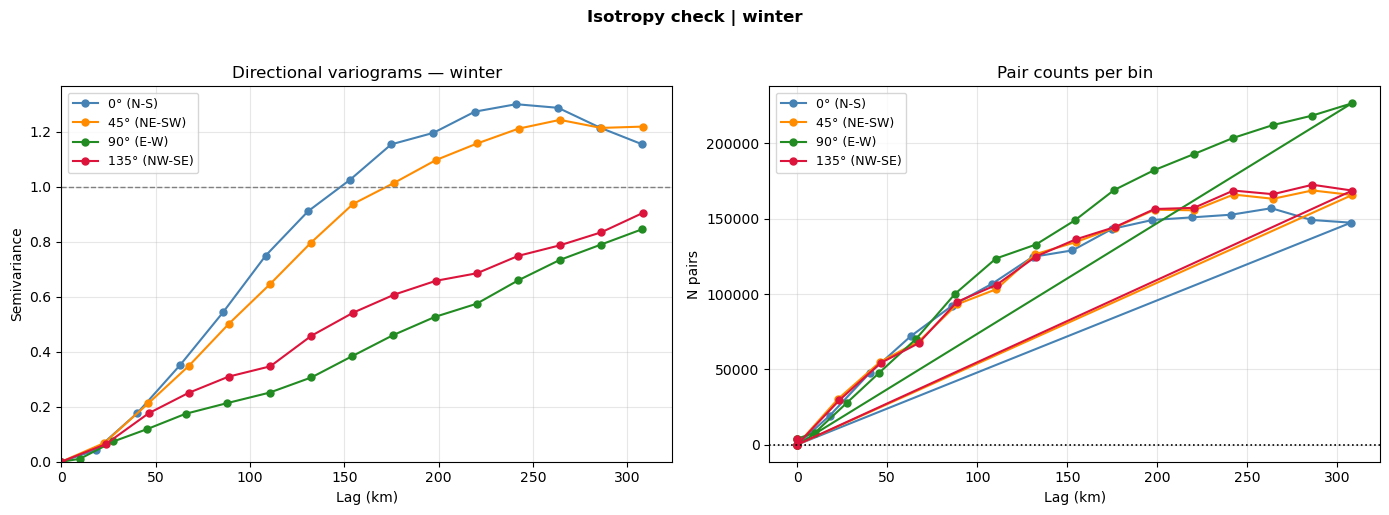

  Anisotropy ratio=0.42  type=mixed  isotropic=False
  spherical    nug=0.000 cc=1.000 range=459.3km R²=1.000 ✓
  exponential  nug=0.000 cc=1.000 range=667.8km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.717 range=345.4km R²=1.000 ⚠ DISQUALIFIED


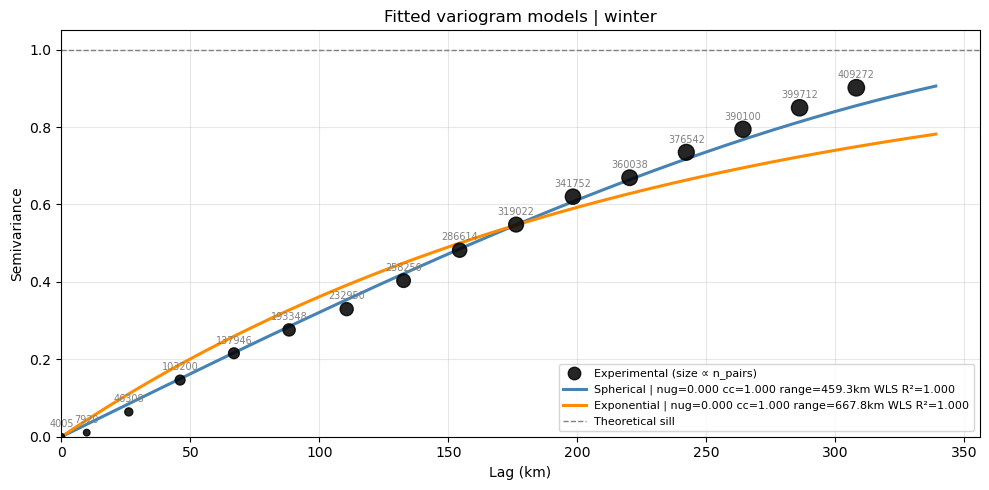


  ✓ Best model: SPHERICAL
  Row saved → ..\Data\Processed\Variogram_analysis\variogram_params_singleDomain.csv

════════════════════════════════════════════════════════════
  Season: pre_monsoon
════════════════════════════════════════════════════════════


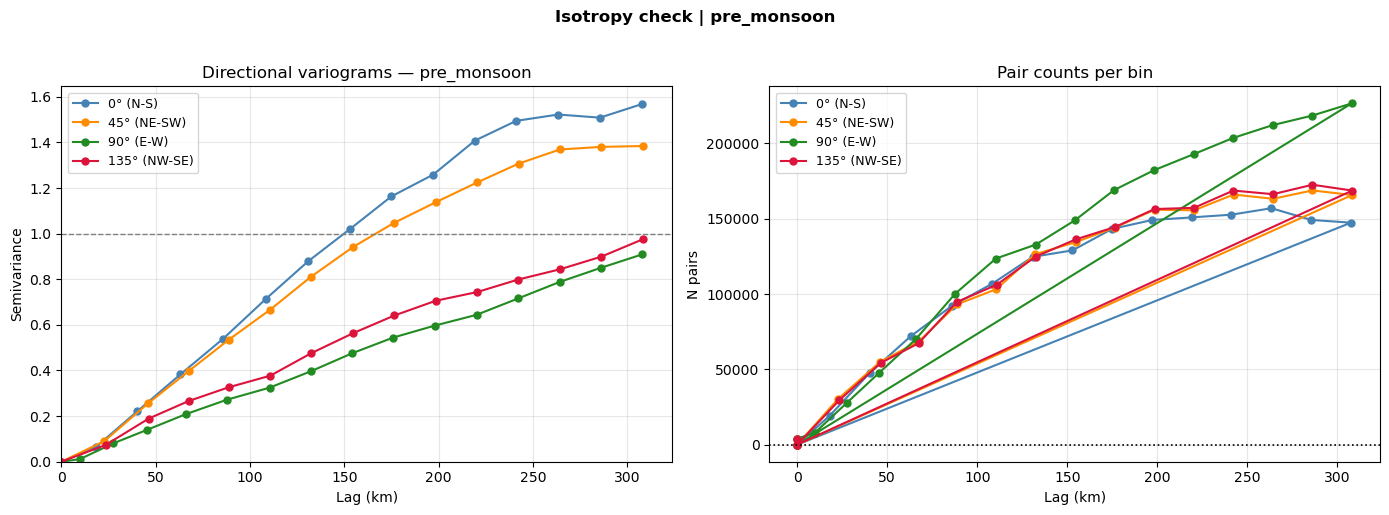

  Anisotropy ratio=0.46  type=mixed  isotropic=False
  spherical    nug=0.000 cc=1.000 range=405.3km R²=1.000 ✓
  exponential  nug=0.000 cc=1.000 range=569.1km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.775 range=328.8km R²=1.000 ⚠ DISQUALIFIED


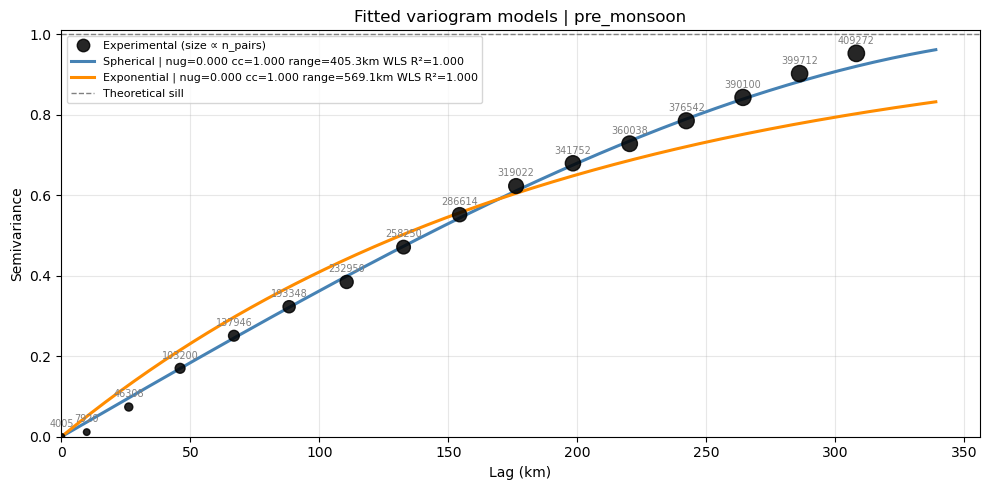


  ✓ Best model: EXPONENTIAL
  Row saved → ..\Data\Processed\Variogram_analysis\variogram_params_singleDomain.csv

════════════════════════════════════════════════════════════
  Season: monsoon
════════════════════════════════════════════════════════════


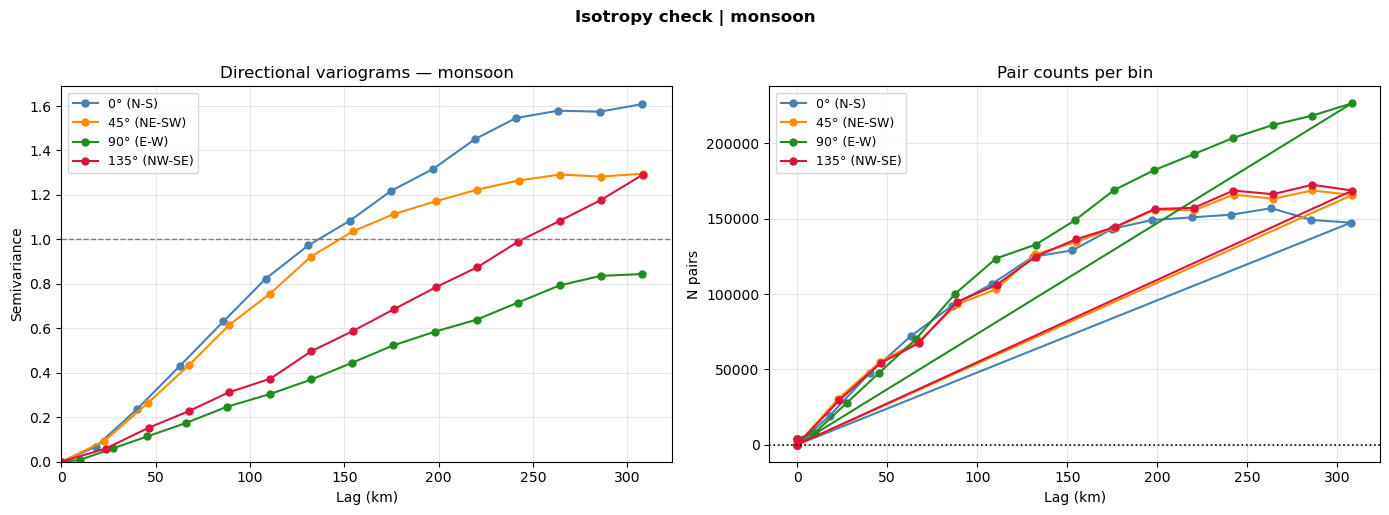

  Anisotropy ratio=0.38  type=mixed  isotropic=False
  spherical    nug=0.000 cc=1.000 range=407.2km R²=1.000 ✓
  exponential  nug=0.000 cc=1.000 range=573.3km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.819 range=369.5km R²=1.000 ⚠ DISQUALIFIED


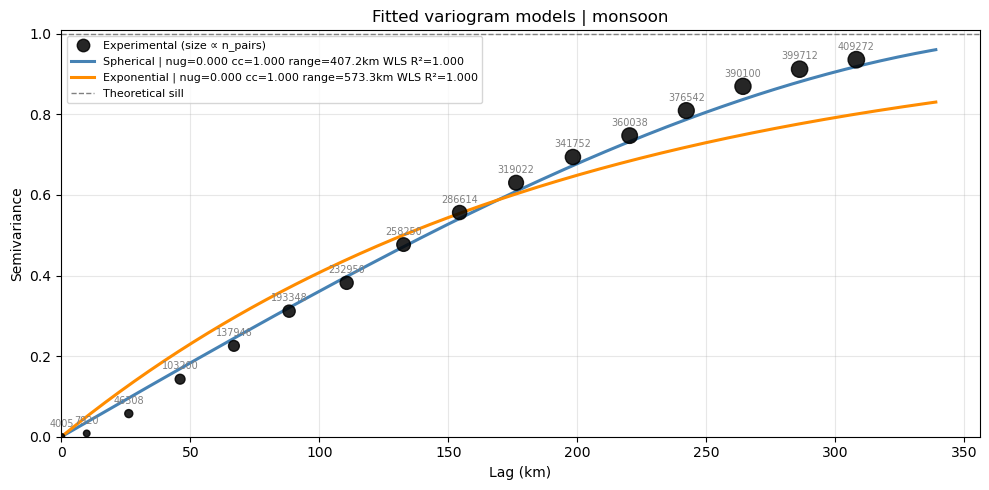


  ✓ Best model: EXPONENTIAL
  Row saved → ..\Data\Processed\Variogram_analysis\variogram_params_singleDomain.csv

════════════════════════════════════════════════════════════
  Season: post_monsoon
════════════════════════════════════════════════════════════


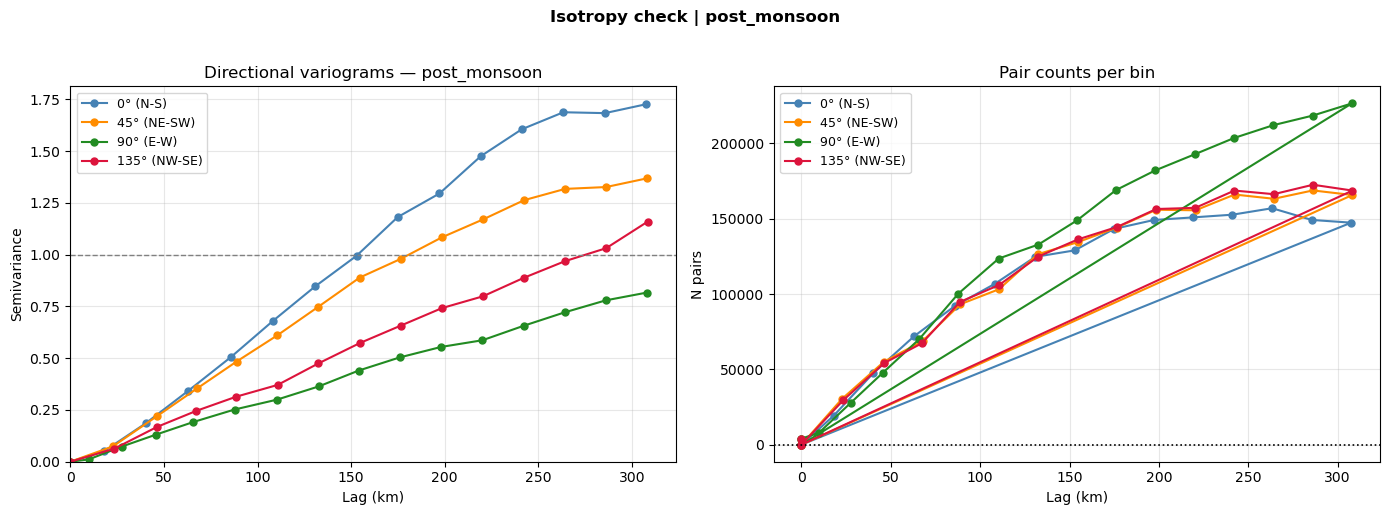

  Anisotropy ratio=0.42  type=mixed  isotropic=False
  spherical    nug=0.000 cc=1.000 range=438.6km R²=1.000 ✓
  exponential  nug=0.000 cc=1.000 range=629.7km R²=1.000 ✓
  gaussian     nug=0.000 cc=0.736 range=337.6km R²=1.000 ⚠ DISQUALIFIED


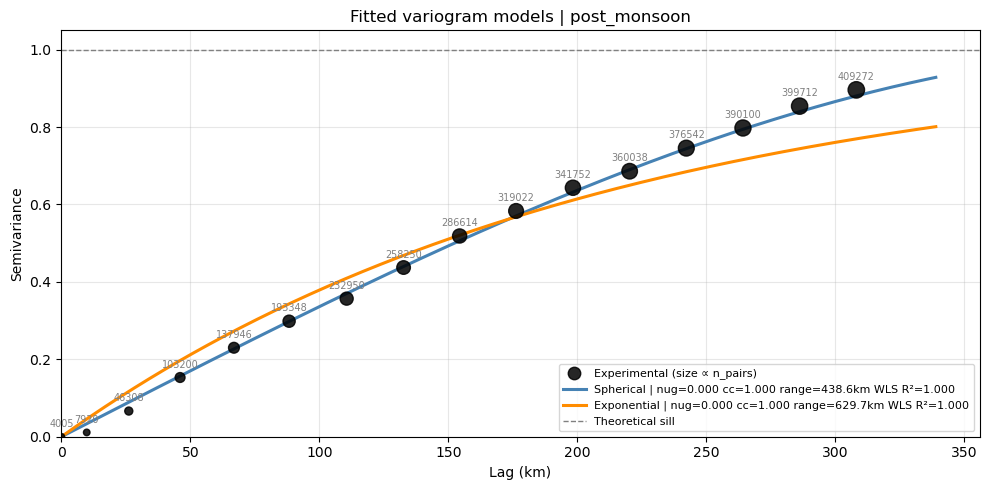


  ✓ Best model: SPHERICAL
  Row saved → ..\Data\Processed\Variogram_analysis\variogram_params_singleDomain.csv

════════════════════════════════════════════════════════════
  Complete. Parameters → ..\Data\Processed\Variogram_analysis\variogram_params_singleDomain.csv
════════════════════════════════════════════════════════════


In [5]:
for season in seasons:
    print(f"\n{'═'*60}")
    print(f"  Season: {season}")
    print(f"{'═'*60}")
    notes = []

    # ── Step 1 — Load & subset ─────────────────────────────────────────────
    clim_rxr = rxr.open_rasterio(
        os.path.join(temp_dir, f"{season}_clim.tif")
    ).squeeze('band', drop=True)


    df = clim_rxr.to_dataframe(name='prec').reset_index()
    df = df.drop(columns=[c for c in ['spatial_ref', 'band'] if c in df.columns])
    df = df.dropna().reset_index(drop=True)

    proj      = Proj("+proj=utm +zone=45 +ellps=WGS84 +datum=WGS84 +units=m +no_defs")
    x_m, y_m  = proj(df['x'].values, df['y'].values)
    df['x_km'] = x_m / 1000.0
    df['y_km'] = y_m / 1000.0
    df = df[['x_km', 'y_km', 'prec']].copy()
    

    if len(df) < 30:
        print(f"  ⚠ Skipping — only {len(df)} pixels")
        continue

    # ── Step 2 — Detrend ───────────────────────────────────────────────────
    trend_removed = False
    r2_trend = 0.0
    coef_x = coef_y = coef_x2 = coef_xy = coef_y2 = 0.0
    intercept = float(df['prec'].mean())
    
    # We use the raw precipitation for the spatial analysis
    residuals =  df['prec'].values

    # ── Step 3 — N-score transform ─────────────────────────────────────────
    ns_data, t_values, t_nscore = geostats.nscore(
        pd.DataFrame({'val': residuals}), 'val'
    )
    df['ns']    = ns_data
    sample_var_ns = float(np.var(ns_data))

    if abs(sample_var_ns - 1.0) > 0.2:
        notes.append(f"nscore_var={sample_var_ns:.3f}")

    lookup_path = os.path.join(temp_dir, f"nscore_lookup_{season}_singleDomain.csv")
    pd.DataFrame({'original_value': t_values, 'nscore_value': t_nscore}).to_csv(
        lookup_path, index=False
    )

    # ── Step 4 — Directional variogram (diagnostic) ────────────────────────
    dir_variograms = {}
    for d in directions:
        lag_h, gamma_h, npairs_h = geostats.gamv(
            df, 'x_km', 'y_km', 'ns',
            tmin, tmax,
            lag_dist, lag_tol, n_lag,
            d['azm'], d['atol'], bandwh, isill=0
        )
        dir_variograms[d['label']] = {'lag': lag_h, 'gamma': gamma_h, 'npairs': npairs_h}

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors_dir = ['steelblue', 'darkorange', 'forestgreen', 'crimson']

    for (label, vdata), color in zip(dir_variograms.items(), colors_dir):
        valid = np.isfinite(vdata['gamma']) & (vdata['npairs'] > 5)
        axes[0].plot(vdata['lag'][valid], vdata['gamma'][valid],
                     'o-', color=color, label=label, linewidth=1.5, markersize=5)
    axes[0].axhline(1.0, color='gray', linestyle='--', linewidth=1)
    axes[0].set(xlabel='Lag (km)', ylabel='Semivariance',
                title=f'Directional variograms — {season}')
    axes[0].legend(fontsize=9); axes[0].grid(True, alpha=0.3)
    axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)

    for (label, vdata), color in zip(dir_variograms.items(), colors_dir):
        valid = np.isfinite(vdata['npairs'])
        axes[1].plot(vdata['lag'][valid], vdata['npairs'][valid],
                     'o-', color=color, label=label, linewidth=1.5, markersize=5)
    axes[1].axhline(30, color='black', linestyle=':', linewidth=1.2)
    axes[1].set(xlabel='Lag (km)', ylabel='N pairs', title='Pair counts per bin')
    axes[1].legend(fontsize=9); axes[1].grid(True, alpha=0.3)

    plt.suptitle(f'Isotropy check | {season}',
                 fontweight='bold', y=1.02)
    plt.tight_layout(); plt.show()

    iso_ranges = {}
    for label, vdata in dir_variograms.items():
        valid   = np.isfinite(vdata['gamma']) & (vdata['npairs'] > 5)
        crossed = vdata['lag'][valid][vdata['gamma'][valid] >= sill_target]
        iso_ranges[label] = float(crossed[0]) if len(crossed) > 0 else np.nan

    valid_ranges = [r for r in iso_ranges.values() if not np.isnan(r)]
    if len(valid_ranges) >= 2:
        anis_ratio     = min(valid_ranges) / max(valid_ranges)
        isotropic_flag = anis_ratio >= 0.5
        plateau_sills  = []
        for vdata in dir_variograms.values():
            valid = np.isfinite(vdata['gamma']) & (vdata['npairs'] > 30)
            if valid.sum() > 0:
                plateau_sills.append(float(np.mean(vdata['gamma'][valid][-3:])))
        sill_ratio     = max(plateau_sills) / min(plateau_sills) if plateau_sills else np.nan
        anisotropy_type = 'geometric' if (np.isnan(sill_ratio) or sill_ratio <= 1.3) else 'mixed'
    else:
        anis_ratio = isotropic_flag = 1.0
        sill_ratio = np.nan
        anisotropy_type = 'unknown'

    major_label    = max(iso_ranges, key=lambda k: iso_ranges[k] if not np.isnan(iso_ranges[k]) else -1)
    minor_label    = min(iso_ranges, key=lambda k: iso_ranges[k] if not np.isnan(iso_ranges[k]) else 9999)
    azm_major      = next(d['azm'] for d in directions if d['label'] == major_label)
    range_major_km = iso_ranges.get(major_label, np.nan)
    range_minor_km = iso_ranges.get(minor_label, np.nan)

    print(f"  Anisotropy ratio={anis_ratio:.2f}  type={anisotropy_type}  isotropic={isotropic_flag}")

    if sill_ratio > 1.3:
        notes.append(f"possible_zonal_anisotropy sill_ratio={sill_ratio:.2f}")

    # ── Step 5 — Experimental variogram + guards ───────────────────────────
    cluster_extent = pdist(df[['x_km', 'y_km']].values).max()
    lag_cap        = cluster_extent / 2.0

    if anis_ratio < 0.8:
        fit_azm, fit_atol   = azm_major, 45
        directions_used     = f'{azm_major}°±45°'
    else:
        fit_azm, fit_atol   = 0, 90
        directions_used     = 'omnidirectional'

    lag_exp, gamma_exp, n_pairs = geostats.gamv(
        df, 'x_km', 'y_km', 'ns',
        tmin, tmax,
        lag_dist, lag_tol, n_lag,
        fit_azm, fit_atol, bandwh, isill=0
    )

    valid_bins  = (n_pairs >= 30) & (lag_exp <= lag_cap)
    lag_fit     = lag_exp[valid_bins]
    gamma_fit   = gamma_exp[valid_bins]
    npairs_fit  = n_pairs[valid_bins]
    n_pairs_min = int(npairs_fit.min()) if len(npairs_fit) > 0 else 0
    n_bins      = len(lag_fit)

    if n_bins < 4:
        print(f"  ⚠ Skipping — only {n_bins} valid bins")
        continue

    # ── Step 6 — Iterative WLS for all three models ────────────────────────
    range_init = iso_ranges.get(major_label, lag_fit.mean())
    p0         = [0.05, 0.90, range_init]
    bounds     = ([0, 0, lag_dist], [1.0, 1.0, 2 * cluster_extent])

    wls_results = {}

    for model_name, func in model_functions.items():
        try:
            popt, sigma_final, converged, history = iterative_wls(
                func, lag_fit, gamma_fit, npairs_fit, p0, bounds, n_bins
            )
            nugget, partial_sill, range_km = popt
            gamma_model = func(lag_fit, *popt)

            ss_res   = np.sum(((gamma_fit - gamma_model) / sigma_final)**2)
            ss_tot   = np.sum(((gamma_fit - gamma_fit.mean()) / sigma_final)**2)
            wls_r2   = float(1 - ss_res / ss_tot) if ss_tot > 1e-12 else np.nan
            wls_rmse = float(np.sqrt(np.mean((gamma_fit - gamma_model)**2)))
            sill_flag = abs(nugget + partial_sill - 1.0) > 0.2

            # Gaussian condition number check
            if model_name == 'gaussian':
                dist_mat  = pdist(df[['x_km', 'y_km']].values)
                from scipy.spatial.distance import squareform
                D         = squareform(dist_mat)
                sill_val  = nugget + partial_sill
                cov_mat   = sill_val - func(D, nugget, partial_sill, range_km)
                n_pts     = len(df)
                C_ok      = np.ones((n_pts+1, n_pts+1))
                C_ok[:n_pts, :n_pts] = cov_mat
                C_ok[n_pts, n_pts]   = 0.0
                cond_number = float(np.linalg.cond(C_ok))
                disqualified = cond_number > 1e5
                disq_reason  = f'cond_number={cond_number:.2e}' if disqualified else None
            else:
                cond_number  = np.nan
                disqualified = False
                disq_reason  = None

            if sill_flag:
                notes.append(f"{model_name}_sill_flag")

            wls_results[model_name] = {
                'func':          func,
                'nugget':        float(nugget),
                'partial_sill':  float(partial_sill),
                'total_sill':    float(nugget + partial_sill),
                'range_km':      float(range_km),
                'wls_r2':        wls_r2,
                'wls_rmse':      wls_rmse,
                'sigma_final':   sigma_final,
                'sill_flag':     sill_flag,
                'cond_number':   cond_number,
                'disqualified':  disqualified,
                'disq_reason':   disq_reason,
            }

            status = '⚠ DISQUALIFIED' if disqualified else ('⚠ SILL FLAG' if sill_flag else '✓')
            print(f"  {model_name:<12} nug={nugget:.3f} cc={partial_sill:.3f} "
                  f"range={range_km:.1f}km R²={wls_r2:.3f} {status}")

        except RuntimeError as e:
            print(f"  {model_name:<12} FAILED — {e}")
            wls_results[model_name] = {
                'disqualified': True, 'disq_reason': str(e),
                'wls_r2': np.nan, 'cond_number': np.nan
            }

    # ── Step 7a — Parameter override block ────────────────────────────────
    model_params = {}
    for model_name, res in wls_results.items():
        if res.get('disqualified'):
            continue
        model_params[model_name] = {
            'nugget':       res['nugget'],
            'partial_sill': res['partial_sill'],
            'range_km':     res['range_km'],
        }

    # Uncomment to override:
    # model_params['spherical']['nugget']        = 0.05
    # model_params['spherical']['partial_sill']  = 0.88
    # model_params['spherical']['range_km']      = 145.0
    # model_params['exponential']['nugget']      = 0.05
    # model_params['exponential']['partial_sill']= 0.90
    # model_params['exponential']['range_km']    = 180.0
    # model_params['gaussian']['nugget']         = 0.02
    # model_params['gaussian']['partial_sill']   = 0.92
    # model_params['gaussian']['range_km']       = 120.0

    # ── Step 7b — Visual comparison ───────────────────────────────────────
    h_plot = np.linspace(0, lag_fit.max() * 1.1, 300)
    fig, ax = plt.subplots(figsize=(10, 5))

    scatter_sizes = (npairs_fit / npairs_fit.max()) * 120 + 20
    ax.scatter(lag_fit, gamma_fit, s=scatter_sizes, color='black',
               zorder=5, label='Experimental (size ∝ n_pairs)', alpha=0.85)
    for h, g, n in zip(lag_fit, gamma_fit, npairs_fit):
        ax.annotate(str(int(n)), (h, g), textcoords='offset points',
                    xytext=(0, 7), ha='center', fontsize=7, color='gray')

    for model_name, params in model_params.items():
        gamma_curve = model_functions[model_name](
            h_plot, params['nugget'], params['partial_sill'], params['range_km']
        )
        wls_r2 = wls_results[model_name]['wls_r2']
        ax.plot(h_plot, gamma_curve, color=COLORS[model_name], linewidth=2.2,
                label=(f"{model_name.capitalize()} | nug={params['nugget']:.3f} "
                       f"cc={params['partial_sill']:.3f} range={params['range_km']:.1f}km "
                       f"WLS R²={wls_r2:.3f}"))

    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1, label='Theoretical sill')
    ax.set(xlabel='Lag (km)', ylabel='Semivariance',
           title=f'Fitted variogram models | {season}')
    ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
    ax.set_xlim(left=0); ax.set_ylim(bottom=0)
    plt.tight_layout(); plt.show()


    # ── Step 8 — Model selection & save ───────────────────────────────────
    qualified = {
        m: wls_results[m] for m in model_params
        if not wls_results[m]['sill_flag'] and not wls_results[m]['disqualified']
    }
    if not qualified:
        qualified = {m: wls_results[m] for m in model_params
                     if not wls_results[m]['disqualified']}
        notes.append('no_model_passed_sill_check')

    # Model chosen strictly by max WLS R-squared
    best_model = max(
        qualified,
        key=lambda m: wls_results[m]['wls_r2']
    )
    
    best_params = model_params[best_model]
    best_wls    = wls_results[best_model]

    if best_wls['wls_r2'] < 0.5:
        notes.append('wls_r2<0.5')
    if best_wls['nugget'] > 0.5 * best_wls['total_sill'] if 'total_sill' in best_wls else False:
        notes.append('nugget_dominated')
    if best_params['range_km'] < 1.5 * lag_dist:
        notes.append('range_too_short')

    print(f"\n  ✓ Best model: {best_model.upper()}")

    row = {
        'season': season,
        'trend_removed': False, 'r2_trend': 0.0,
        'coef_x': 0.0, 'coef_y': 0.0, 'coef_x2': 0.0, 'coef_xy': 0.0, 'coef_y2': 0.0, 'intercept': intercept,
        'nscore_lookup_path': lookup_path, 'sample_var_ns': round(sample_var_ns, 6),
        'azimuth_major': azm_major, 'range_km': round(best_params['range_km'], 3),
        'model_type': best_model, 'nugget': round(best_params['nugget'], 6),
        'partial_sill': round(best_params['partial_sill'], 6),
        'wls_r2': round(best_wls['wls_r2'], 6)
    }
    pd.DataFrame([row]).to_csv(params_csv, mode='a', header=not os.path.exists(params_csv), index=False)
    print(f"  Row saved → {params_csv}")

print(f"\n{'═'*60}")
print(f"  Complete. Parameters → {params_csv}")
print(f"{'═'*60}")